[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Shreyashgol/phonetic-guided-speech-generation/blob/main/notebooks/14_evaluation_duration_swap.ipynb)

# 14 · Evaluation: does a better duration model give better speech?
**Goal:** answer the project's central question with numbers and a listening test: *does the Phase 1 duration predictor improve synthesis compared with simpler duration sources?*

**Use a GPU:** Runtime -> Change runtime type -> T4.

**Design decisions (put these in the report)**
- **Same acoustic model, only the durations change.** Five conditions on the **test** utterances: (A) ground-truth durations (upper bound), (B) Phase 1 BiLSTM, (C) phone-mean baseline, (D) global mean, (E) the acoustic model's own duration head.
- **Controlled comparison:** Phase 1 predicts speech-phone durations only, so silence tokens keep their ground-truth lengths in every condition. Only speech-phone durations differ.
- **Objective metric:** log-mel L1 after **dynamic time warping** (DTW). Different durations give different lengths, so frames must be matched before comparing. We also report the absolute error of total length in frames. Intervals are 95% bootstrap CIs over utterances.
- **Subjective metric:** a blind 1–5 naturalness listening test (MOS) on 10 utterances × 4 conditions (natural-vocoded, ground-truth durations, Phase 1 BiLSTM, phone-mean). Files get random codes, so raters cannot know the condition.
- **Honest limits:** DTW mel distance is a proxy, not quality. The listening test is small. Say both in the report.

**Reads:** best checkpoint, test split, `features.csv.gz`, `preds_*.csv` (Phase 1). **Writes:** `results/14_objective.csv`, `results/14_objective.png`, `results/listening/*`.

In [ ]:
# ---- Cell 0: Setup (identical at the top of every notebook)
import os, sys, json, glob
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/phonetic-tts'
    IN_COLAB = True
except ImportError:                      # running somewhere else (local / tests)
    PROJECT_ROOT = os.environ.get('PROJECT_ROOT', os.getcwd())
    IN_COLAB = False
sys.path.insert(0, PROJECT_ROOT)
from src.utils.config import load_config
cfg = load_config(PROJECT_ROOT)
A = cfg['audio']; P = cfg['abs_paths']
RAW, PROCESSED, ALIGN, SPLITS, RESULTS = P['raw'], P['processed'], P['alignments'], P['splits'], P['results']
for d in (PROCESSED, ALIGN, SPLITS, RESULTS):
    os.makedirs(d, exist_ok=True)
print('Project root:', PROJECT_ROOT, '| Colab:', IN_COLAB)

Mounted at /content/drive
Project root: /content/drive/MyDrive/phonetic-tts | Colab: True


In [ ]:
%%bash
pip -q install speechbrain

In [ ]:
# ---- Write shared module: mel extractor
import os, importlib
_src = r'''"""Mel recipe shared by notebooks 10-14. Must stay identical to the vocoder's recipe (see notebook 10)."""
import numpy as np, soundfile as sf, librosa, scipy.signal


class MelExtractor:
    def __init__(self, sr=22050, n_fft=1024, hop=256, win=1024, n_mels=80, fmin=0, fmax=8000):
        self.sr, self.n_fft, self.hop, self.win = sr, n_fft, hop, win
        self.basis = librosa.filters.mel(sr=sr, n_fft=n_fft, n_mels=n_mels, fmin=fmin, fmax=fmax)
        self.window = scipy.signal.get_window('hann', win, fftbins=True)

    def from_array(self, y):
        y = np.asarray(y, dtype=np.float32)
        pad = (self.n_fft - self.hop) // 2
        y = np.pad(y, (pad, pad), mode='reflect')
        S = librosa.stft(y, n_fft=self.n_fft, hop_length=self.hop, win_length=self.win, window=self.window, center=False)
        mag = np.sqrt(S.real ** 2 + S.imag ** 2 + 1e-9)
        return np.log(np.clip(self.basis @ mag, 1e-5, None)).T.astype(np.float32)      # (frames, n_mels)

    def from_file(self, path):
        y, sr = sf.read(path, dtype='float32')
        assert sr == self.sr, f'{path}: sample rate {sr}'
        return self.from_array(y.mean(1) if y.ndim > 1 else y)
'''
_p = os.path.join(PROJECT_ROOT, "src/features/mel.py")
os.makedirs(os.path.dirname(_p), exist_ok=True)
for _d in ["src", os.path.dirname("src/features/mel.py")]:
    open(os.path.join(PROJECT_ROOT, _d, "__init__.py"), "a").close()
open(_p, "w").write(_src)
importlib.invalidate_caches()
print("wrote", _p)

wrote /content/drive/MyDrive/phonetic-tts/src/features/mel.py


In [ ]:
# ---- Write shared module: pretrained HiFi-GAN wrapper
import os, importlib
_src = r'''"""Pretrained HiFi-GAN (SpeechBrain, trained on LJSpeech at 22.05 kHz, 80 mels, hop 256)."""
import torch


class Vocoder:
    def __init__(self, device='cpu', savedir='pretrained_hifigan'):
        try:
            from speechbrain.inference.vocoders import HIFIGAN
        except ImportError:                                   # older speechbrain
            from speechbrain.pretrained import HIFIGAN
        self.device = device
        self.m = HIFIGAN.from_hparams(source='speechbrain/tts-hifigan-ljspeech', savedir=savedir, run_opts={'device': device})

    @torch.no_grad()
    def __call__(self, mel):
        """mel: (B, T, 80) or (T, 80) log-mel in natural units (NOT normalised) -> waveform (B, T*256) float tensor on CPU."""
        if mel.dim() == 2: mel = mel.unsqueeze(0)
        w = self.m.decode_batch(mel.transpose(1, 2).float().to(self.device))
        return w.reshape(w.shape[0], -1).cpu()
'''
_p = os.path.join(PROJECT_ROOT, "src/vocoder/hifigan.py")
os.makedirs(os.path.dirname(_p), exist_ok=True)
for _d in ["src", os.path.dirname("src/vocoder/hifigan.py")]:
    open(os.path.join(PROJECT_ROOT, _d, "__init__.py"), "a").close()
open(_p, "w").write(_src)
importlib.invalidate_caches()
print("wrote", _p)

wrote /content/drive/MyDrive/phonetic-tts/src/vocoder/hifigan.py


In [ ]:
# ---- Write shared module: dataset
import os, importlib
_src = r'''"""Phase 2 data loading: manifest + mels from notebook 10."""
import json, os
import numpy as np, pandas as pd, torch
from torch.utils.data import Dataset, Sampler


class TTSDataset(Dataset):
    def __init__(self, processed_dir, split, max_items=None):
        df = pd.read_csv(os.path.join(processed_dir, 'phase2_manifest.csv'))
        df = df[df.split == split].reset_index(drop=True)
        if max_items: df = df.iloc[:max_items]
        st = json.load(open(os.path.join(processed_dir, 'mel_stats.json')))
        self.mean = np.array(st['mean'], np.float32); self.std = np.array(st['std'], np.float32) + 1e-5
        self.mel_dir = os.path.join(processed_dir, 'mels')
        self.ids = df.utt_id.tolist(); self.n_frames = df.n_frames.to_numpy()
        self.tokens = [np.array(s.split(), np.int64) for s in df.tokens]
        self.stress = [np.array(s.split(), np.int64) for s in df.stress]
        self.durs = [np.array(s.split(), np.int64) for s in df.durations]

    def __len__(self):
        return len(self.ids)

    def mel(self, i):
        m = np.load(os.path.join(self.mel_dir, self.ids[i] + '.npy')).astype(np.float32)
        return (m - self.mean) / self.std

    def __getitem__(self, i):
        return dict(id=self.ids[i], tok=torch.from_numpy(self.tokens[i]), stress=torch.from_numpy(self.stress[i]),
                    dur=torch.from_numpy(self.durs[i]), mel=torch.from_numpy(self.mel(i)))


def collate(batch):
    B = len(batch); T = max(len(b['tok']) for b in batch); M = max(len(b['mel']) for b in batch)
    n_mels = batch[0]['mel'].shape[1]
    tok = torch.zeros(B, T, dtype=torch.long); st = torch.zeros(B, T, dtype=torch.long)
    dur = torch.zeros(B, T, dtype=torch.long); mel = torch.zeros(B, M, n_mels)
    for i, b in enumerate(batch):
        t, m = len(b['tok']), len(b['mel'])
        tok[i, :t] = b['tok']; st[i, :t] = b['stress']; dur[i, :t] = b['dur']; mel[i, :m] = b['mel']
    return dict(ids=[b['id'] for b in batch], tok=tok, stress=st, dur=dur, mel=mel,
                mel_len=torch.tensor([len(b['mel']) for b in batch]))


class BucketSampler(Sampler):
    """Batches of similar length (less padding), shuffled each epoch."""
    def __init__(self, n_frames, batch_size, shuffle=True, seed=0):
        self.n = np.asarray(n_frames); self.bs = batch_size; self.shuffle = shuffle; self.epoch = 0; self.seed = seed

    def __iter__(self):
        rng = np.random.RandomState(self.seed + self.epoch); self.epoch += 1
        idx = rng.permutation(len(self.n)) if self.shuffle else np.arange(len(self.n))
        chunk = self.bs * 50
        batches = []
        for s in range(0, len(idx), chunk):
            c = idx[s:s + chunk]; c = c[np.argsort(self.n[c])]
            batches += [c[j:j + self.bs].tolist() for j in range(0, len(c), self.bs)]
        if self.shuffle: rng.shuffle(batches)
        return iter(batches)

    def __len__(self):
        return (len(self.n) + self.bs - 1) // self.bs
'''
_p = os.path.join(PROJECT_ROOT, "src/data/tts_dataset.py")
os.makedirs(os.path.dirname(_p), exist_ok=True)
for _d in ["src", os.path.dirname("src/data/tts_dataset.py")]:
    open(os.path.join(PROJECT_ROOT, _d, "__init__.py"), "a").close()
open(_p, "w").write(_src)
importlib.invalidate_caches()
print("wrote", _p)

wrote /content/drive/MyDrive/phonetic-tts/src/data/tts_dataset.py


In [ ]:
# ---- Write shared module: acoustic model
import os, importlib
_src = r'''"""FastSpeech 2-style acoustic model (phonemes + durations -> mel). No pitch/energy predictors (added later as an ablation)."""
import math
import torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence


def sinusoid(n, d):
    pos = torch.arange(n).unsqueeze(1).float()
    ang = pos / torch.pow(10000.0, torch.arange(0, d, 2).float() / d)
    pe = torch.zeros(n, d); pe[:, 0::2] = torch.sin(ang); pe[:, 1::2] = torch.cos(ang)
    return pe


class FFTBlock(nn.Module):
    """Self-attention + 1D-conv feed-forward, post-LayerNorm (as in FastSpeech)."""
    def __init__(self, d, heads, ffn, k, p):
        super().__init__()
        self.attn = nn.MultiheadAttention(d, heads, dropout=p, batch_first=True)
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.c1 = nn.Conv1d(d, ffn, k, padding=k // 2); self.c2 = nn.Conv1d(ffn, d, 1)
        self.drop = nn.Dropout(p)

    def forward(self, x, pad):                       # x (B,T,D); pad (B,T) True = padding
        a, _ = self.attn(x, x, x, key_padding_mask=pad, need_weights=False)
        x = self.n1(x + self.drop(a))
        y = x.masked_fill(pad.unsqueeze(-1), 0).transpose(1, 2)
        y = self.c2(F.relu(self.c1(y))).transpose(1, 2)
        x = self.n2(x + self.drop(y))
        return x.masked_fill(pad.unsqueeze(-1), 0)


class DurationPredictor(nn.Module):
    """Predicts log(frames + 1) per token (the model's own duration head)."""
    def __init__(self, d, k=3, p=0.2):
        super().__init__()
        self.c1 = nn.Conv1d(d, d, k, padding=k // 2); self.n1 = nn.LayerNorm(d)
        self.c2 = nn.Conv1d(d, d, k, padding=k // 2); self.n2 = nn.LayerNorm(d)
        self.out = nn.Linear(d, 1); self.drop = nn.Dropout(p)

    def forward(self, x, pad):
        m = pad.unsqueeze(-1)
        y = self.drop(self.n1(F.relu(self.c1(x.masked_fill(m, 0).transpose(1, 2))).transpose(1, 2)))
        y = self.drop(self.n2(F.relu(self.c2(y.masked_fill(m, 0).transpose(1, 2))).transpose(1, 2)))
        return self.out(y).squeeze(-1).masked_fill(pad, 0)


def length_regulate(x, dur):
    """Repeat each token vector dur[b, t] times. x (B,T,D), dur (B,T) long -> (B,M,D), lengths (B,)"""
    outs = [torch.repeat_interleave(x[b], dur[b], dim=0) for b in range(x.size(0))]
    lens = torch.tensor([o.size(0) for o in outs], device=x.device)
    return pad_sequence(outs, batch_first=True), lens


class AcousticModel(nn.Module):
    def __init__(self, n_vocab, n_mels=80, d=256, heads=2, ffn=768, k=3, n_enc=4, n_dec=4, p=0.1, max_len=1600):
        super().__init__()
        self.tok = nn.Embedding(n_vocab, d, padding_idx=0); self.stress = nn.Embedding(4, d)
        self.register_buffer('pe', sinusoid(max_len, d), persistent=False)
        self.enc = nn.ModuleList([FFTBlock(d, heads, ffn, k, p) for _ in range(n_enc)])
        self.dec = nn.ModuleList([FFTBlock(d, heads, ffn, k, p) for _ in range(n_dec)])
        self.dp = DurationPredictor(d); self.out = nn.Linear(d, n_mels)

    def forward(self, tok, stress, dur=None, alpha=1.0):
        """dur given -> teacher forcing (training / ground truth / Phase 1 durations). dur None -> own duration head."""
        pad = tok == 0
        x = self.tok(tok) + self.stress(stress) + self.pe[:tok.size(1)]
        for b in self.enc: x = b(x, pad)
        logd = self.dp(x, pad)
        if dur is None:
            dur = torch.clamp(torch.round((torch.exp(logd) - 1) * alpha), min=1).long().masked_fill(pad, 0)
        y, lens = length_regulate(x, dur)
        mpad = torch.arange(y.size(1), device=y.device)[None] >= lens[:, None]
        y = (y + self.pe[:y.size(1)]).masked_fill(mpad.unsqueeze(-1), 0)
        for b in self.dec: y = b(y, mpad)
        return dict(mel=self.out(y), logd=logd, tok_pad=pad, mel_pad=mpad, dur=dur)


def acoustic_loss(o, mel, dur):
    """masked L1 on mel + masked MSE on log-duration."""
    assert o['mel'].shape == mel.shape, (o['mel'].shape, mel.shape)
    m = (~o['mel_pad']).unsqueeze(-1).float()
    mel_l = ((o['mel'] - mel).abs() * m).sum() / (m.sum() * mel.size(-1))
    t = (~o['tok_pad']).float()
    dur_l = (((o['logd'] - torch.log(dur.float() + 1)) ** 2) * t).sum() / t.sum()
    return mel_l + dur_l, mel_l, dur_l
'''
_p = os.path.join(PROJECT_ROOT, "src/models/acoustic/model.py")
os.makedirs(os.path.dirname(_p), exist_ok=True)
for _d in ["src", os.path.dirname("src/models/acoustic/model.py")]:
    open(os.path.join(PROJECT_ROOT, _d, "__init__.py"), "a").close()
open(_p, "w").write(_src)
importlib.invalidate_caches()
print("wrote", _p)

wrote /content/drive/MyDrive/phonetic-tts/src/models/acoustic/model.py


## Step 1: Load model, data and Phase 1 predictions

In [ ]:
import numpy as np, pandas as pd, torch, librosa, soundfile as sf, random
from src.data.tts_dataset import TTSDataset
from src.models.acoustic.model import AcousticModel
from src.features.mel import MelExtractor
from src.vocoder.hifigan import Vocoder
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
contract = json.load(open(os.path.join(PROCESSED, 'phase2_contract.json'))); VOCAB = contract['vocab']; SIL = VOCAB['sil']
ck = torch.load(os.path.join(PROJECT_ROOT, 'checkpoints', 'acoustic', 'best.pt'), map_location=DEV, weights_only=False)
model = AcousticModel(len(VOCAB), A['n_mels'], **ck['arch']).to(DEV); model.load_state_dict(ck['model']); model.eval()
print('loaded checkpoint from step', ck['step'], '| best val mel L1', round(ck['best'], 4))
ds = TTSDataset(PROCESSED, 'test'); MEAN, STD = ds.mean, ds.std
feat = pd.read_csv(os.path.join(PROCESSED, 'features.csv.gz'), usecols=['row_id', 'utt_id', 'phone_idx', 'split'])
feat = feat[feat.split == 'test'].sort_values(['utt_id', 'phone_idx'])
rows_of = {u: g.row_id.to_numpy() for u, g in feat.groupby('utt_id')}
def load_pred(pattern):
    f = sorted(glob.glob(os.path.join(RESULTS, pattern)))[0]; d = pd.read_csv(f); d = d[d.split == 'test']
    print('using', os.path.basename(f), '| test rows', len(d)); return d.set_index('row_id').y_pred
PRED = {'phase1_bilstm': load_pred('preds_bilstm.csv'), 'phone_mean': load_pred('preds_phone_mean*.csv'), 'global_mean': load_pred('preds_global_mean.csv')}

loaded checkpoint from step 8000 | best val mel L1 0.4073
using preds_bilstm.csv | test rows 37916
using preds_phone_mean_median.csv | test rows 37916
using preds_global_mean.csv | test rows 37916


## Step 2: Build the durations for each condition
The speech tokens of an utterance, in order, are exactly the Phase 1 feature rows of that utterance (we clipped speech phones to at least 1 frame in Phase 1, so none were dropped). Utterances where the counts disagree are skipped and counted.

In [ ]:
@torch.no_grad()
def own_duration(i):
    tok = ds.tokens[i]; b = lambda a: torch.from_numpy(a)[None].to(DEV)
    return model(b(ds.tokens[i]), b(ds.stress[i]))['dur'][0].cpu().numpy()

def durations(i, cond):
    gt = ds.durs[i].copy()
    if cond == 'ground_truth': return gt
    sp = ds.tokens[i] != SIL
    if cond == 'own_head':
        d = own_duration(i); d[~sp] = gt[~sp]; return d
    rows = rows_of.get(ds.ids[i])
    if rows is None or len(rows) != sp.sum() or not np.isin(rows, PRED[cond].index).all(): return None
    d = gt.copy(); d[sp] = np.clip(np.round(PRED[cond].loc[rows].to_numpy()), 1, None).astype(np.int64); return d

CONDS = ['ground_truth', 'phase1_bilstm', 'phone_mean', 'global_mean', 'own_head']
rng = np.random.RandomState(0); N_EVAL = 200
cand = [i for i in rng.permutation(len(ds)) if all(durations(i, c) is not None for c in CONDS[1:4])]
EVAL = cand[:N_EVAL]
print(f'test utterances {len(ds)} | usable {len(cand)} | evaluated {len(EVAL)} (change N_EVAL for more)')

test utterances 552 | usable 534 | evaluated 200 (change N_EVAL for more)


## Step 3: Synthesise mels for every condition and measure

In [ ]:
@torch.no_grad()
def synth_mel(i, d):
    b = lambda a: torch.from_numpy(a)[None].to(DEV)
    o = model(b(ds.tokens[i]), b(ds.stress[i]), dur=b(d))
    return o['mel'][0].cpu().numpy() * STD + MEAN                      # natural log-mel

def dtw_l1(a, b):
    D, wp = librosa.sequence.dtw(X=a.T, Y=b.T, metric='cityblock')
    return D[-1, -1] / (len(wp) * a.shape[1])                          # mean per-bin L1 along the path (nats)

res = []
for i in EVAL:
    ref = ds.mel(i) * STD + MEAN; gt_total = int(ds.durs[i].sum())
    for c in CONDS:
        d = durations(i, c); m = synth_mel(i, d)
        res.append(dict(utt_id=ds.ids[i], cond=c, dtw_l1=dtw_l1(m, ref), len_err_frames=abs(int(d.sum()) - gt_total)))
R = pd.DataFrame(res); R.to_csv(os.path.join(RESULTS, '14_objective_per_utt.csv'), index=False)

def boot(x, B=1000, seed=0):
    r = np.random.RandomState(seed); x = np.asarray(x); bs = [x[r.randint(0, len(x), len(x))].mean() for _ in range(B)]
    return x.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)
tab = []
for c in CONDS:
    s = R[R.cond == c]; m, lo, hi = boot(s.dtw_l1); l, llo, lhi = boot(s.len_err_frames)
    tab.append(dict(condition=c, dtw_l1=m, ci_lo=lo, ci_hi=hi, total_len_err_frames=l, len_ci_lo=llo, len_ci_hi=lhi))
T = pd.DataFrame(tab).round(4); T.to_csv(os.path.join(RESULTS, '14_objective.csv'), index=False); T

,condition,dtw_l1,ci_lo,ci_hi,total_len_err_frames,len_ci_lo,len_ci_hi
0,ground_truth,0.6617,0.6562,0.6674,0.000,0.0000,0.0000
1,phase1_bilstm,0.6646,0.6592,0.6702,20.150,17.5998,22.6751
2,phone_mean,0.6782,0.6727,0.6837,48.450,43.5750,53.4701
3,global_mean,0.6859,0.6808,0.6914,42.250,37.6699,47.1006
4,own_head,0.6661,0.6606,0.6715,19.855,17.3249,22.4350


## Step 4: Paired comparison (same utterances, so we compare differences)

In [ ]:
W = R.pivot(index='utt_id', columns='cond', values='dtw_l1')
def paired(a, b):
    d = (W[a] - W[b]).to_numpy(); m, lo, hi = boot(d); return dict(comparison=f'{a} - {b}', mean_diff=m, ci_lo=lo, ci_hi=hi, share_a_better=float((d < 0).mean()))
P = pd.DataFrame([paired('phase1_bilstm', 'phone_mean'), paired('phase1_bilstm', 'global_mean'), paired('phase1_bilstm', 'own_head'),
                  paired('phase1_bilstm', 'ground_truth'), paired('phone_mean', 'ground_truth')]).round(4)
P.to_csv(os.path.join(RESULTS, '14_paired.csv'), index=False); print('negative mean_diff = first condition is closer to the real mel'); P

negative mean_diff = first condition is closer to the real mel


,comparison,mean_diff,ci_lo,ci_hi,share_a_better
0,phase1_bilstm - phone_mean,-0.0136,-0.0155,-0.0116,0.895
1,phase1_bilstm - global_mean,-0.0213,-0.0243,-0.0185,0.920
2,phase1_bilstm - own_head,-0.0015,-0.0023,-0.0005,0.570
3,phase1_bilstm - ground_truth,0.0029,0.0015,0.0043,0.375
4,phone_mean - ground_truth,0.0165,0.0142,0.0187,0.140


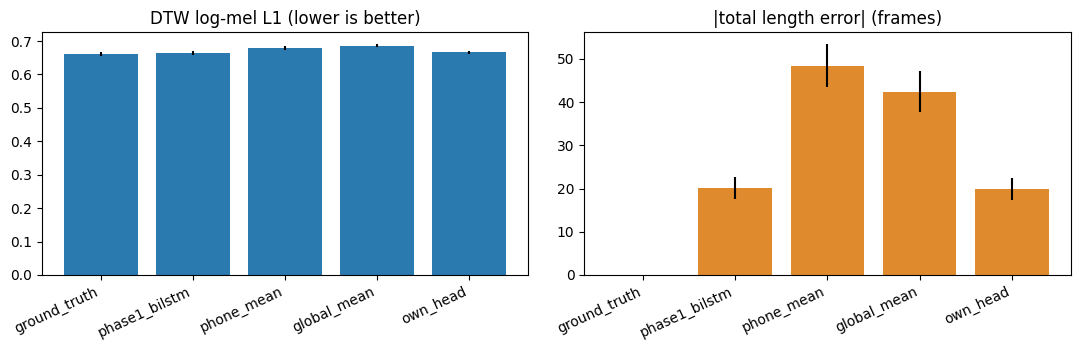

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6)); x = np.arange(len(T))
ax[0].bar(x, T.dtw_l1, yerr=[T.dtw_l1 - T.ci_lo, T.ci_hi - T.dtw_l1], color='#2a7ab0'); ax[0].set_xticks(x); ax[0].set_xticklabels(T.condition, rotation=25, ha='right'); ax[0].set_title('DTW log-mel L1 (lower is better)')
ax[1].bar(x, T.total_len_err_frames, yerr=[T.total_len_err_frames - T.len_ci_lo, T.len_ci_hi - T.total_len_err_frames], color='#e08a2e'); ax[1].set_xticks(x); ax[1].set_xticklabels(T.condition, rotation=25, ha='right'); ax[1].set_title('|total length error| (frames)')
fig.tight_layout(); fig.savefig(os.path.join(RESULTS, '14_objective.png'), dpi=150); plt.show()

## Step 5: Build the blind listening-test pack
10 test utterances (2–8 s) × 4 conditions = 40 clips with random codes. **Share only `listening_pack.zip` and `rating_sheet.csv`.** Keep `PRIVATE_key.csv` to yourselves until all ratings are in.

In [ ]:
import shutil
voc = Vocoder(DEV, os.path.join(PROJECT_ROOT, 'pretrained', 'hifigan'))
LDIR = os.path.join(RESULTS, 'listening'); WAVS = os.path.join(LDIR, 'clips'); shutil.rmtree(LDIR, ignore_errors=True); os.makedirs(WAVS)
LCONDS = {'natural_vocoded': None, 'ground_truth': 'ground_truth', 'phase1_bilstm': 'phase1_bilstm', 'phone_mean': 'phone_mean'}
pick = [i for i in EVAL if 170 <= ds.n_frames[i] <= 700][:10]
codes = [f'C{n:02d}' for n in range(1, len(pick) * len(LCONDS) + 1)]; random.Random(1).shuffle(codes); k = 0; key = []
for i in pick:
    for name, c in LCONDS.items():
        mel = (ds.mel(i) * STD + MEAN) if c is None else synth_mel(i, durations(i, c))
        w = np.clip(voc(torch.from_numpy(mel.astype(np.float32)))[0].numpy(), -1, 1)
        sf.write(os.path.join(WAVS, codes[k] + '.wav'), w, A['sample_rate']); key.append(dict(code=codes[k], utt_id=ds.ids[i], cond=name)); k += 1
pd.DataFrame(key).sort_values('code').to_csv(os.path.join(LDIR, 'PRIVATE_key.csv'), index=False)
pd.DataFrame({'rater': '', 'code': sorted(codes), 'score': ''}).to_csv(os.path.join(LDIR, 'rating_sheet.csv'), index=False)
open(os.path.join(WAVS, 'README.txt'), 'w').write('Rate each clip C01..C40 for naturalness: 1 = bad, 2 = poor, 3 = fair, 4 = good, 5 = excellent. Use headphones. Fill rater (your name), code, score in rating_sheet.csv. Do not discuss clips before everyone has finished.')
shutil.make_archive(os.path.join(LDIR, 'listening_pack'), 'zip', WAVS)
print(len(codes), 'clips ->', os.path.join(LDIR, 'listening_pack.zip'))

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Fetching from HuggingFace Hub 'speechbrain/tts-hifigan-ljspeech' if not cached


hyperparams.yaml:   0%|          | 0.00/1.16k [00:00<?, ?B/s]

INFO:speechbrain.utils.fetching:Fetch generator.ckpt: Fetching from HuggingFace Hub 'speechbrain/tts-hifigan-ljspeech' if not cached


generator.ckpt: reconstructing file:   0%|          |  0.00B / 55.8MB            

generator.ckpt: downloading bytes:           |  0.00B            

INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: generator


40 clips -> /content/drive/MyDrive/phonetic-tts/results/listening/listening_pack.zip


## Step 6: Analyse the ratings (run after everyone has rated)
Each rater fills a copy of `rating_sheet.csv` (same `code`s, with `rater` and `score`). Put all copies into one file `results/listening/ratings.csv`: stack the rows (all with the same columns). This cell then reports mean score per condition with a 95% bootstrap CI over **clips**, and the paired difference Phase 1 BiLSTM vs phone-mean.

In [ ]:
rp = os.path.join(LDIR, 'ratings.csv')
if not os.path.exists(rp):
    print('No ratings.csv yet. After the group has rated, stack all rating_sheet.csv files into', rp)
else:
    rt = pd.read_csv(rp).dropna(subset=['score']); rt = rt.merge(pd.read_csv(os.path.join(LDIR, 'PRIVATE_key.csv')), on='code')
    print('raters:', rt.rater.nunique(), '| ratings:', len(rt))
    per_clip = rt.groupby(['utt_id', 'cond']).score.mean().unstack()          # average over raters first
    out = []
    for c in per_clip.columns:
        m, lo, hi = boot(per_clip[c].to_numpy()); out.append(dict(condition=c, mos=m, ci_lo=lo, ci_hi=hi))
    MOS = pd.DataFrame(out).round(2); MOS.to_csv(os.path.join(RESULTS, '14_mos.csv'), index=False); display(MOS)
    d = (per_clip['phase1_bilstm'] - per_clip['phone_mean']).to_numpy(); m, lo, hi = boot(d)
    print(f'paired MOS difference (Phase 1 BiLSTM - phone mean): {m:.2f} [{lo:.2f}, {hi:.2f}] over {len(d)} utterances')

raters: 3 | ratings: 120


,condition,mos,ci_lo,ci_hi
0,ground_truth,4.17,3.97,4.33
1,natural_vocoded,4.27,4.13,4.43
2,phase1_bilstm,4.13,3.93,4.33
3,phone_mean,4.37,4.17,4.53


paired MOS difference (Phase 1 BiLSTM - phone mean): -0.23 [-0.53, 0.07] over 10 utterances


## What to check before moving on
1. `14_objective.csv`: ground truth should be best, then (hopefully) Phase 1 BiLSTM; a CI that overlaps with phone-mean means **no clear difference** and the report must say so.
2. `14_paired.csv`: look at the sign and the CI of `phase1_bilstm - phone_mean`.
3. Listening test: 3+ raters, headphones, same room. Report the number of raters and clips next to the MOS.
4. If the result is "no clear improvement", that is still a valid finding: say what it means (the vocoder and decoder may mask duration errors; a larger sample is needed).

**Next:** notebook 15 makes the text-to-speech demo and collects the final Phase 2 results for the report and README.